# 22481 · Lesson 9 — My Phantom Investigation
**Group workspace | 6 November 2026 and subsequent project lessons**

**This is your investigation, not a worksheet with fixed answers.** Start with the questions you want to answer about your phantom. You may **practise first** in the companion *Python Image Analysis Toolbox* or **start directly with your own data**. Move between them as needed.

You are welcome to copy, adapt and combine toolbox functions; you are **not expected to write image-processing functions from scratch**. However, you should understand what your code measures and be able to justify ROI locations, line endpoints, processing choices, units and limitations. Your group decides which analyses are meaningful.

**Aim:** Build reproducible evidence from ultrasound, X-ray, CT and MRI, then communicate it in a coherent scientific report. Duplicate or reorganise sections as your investigation develops; the structure below is a suggested workspace, not a prescribed sequence.

## 1 · Group and research plan
**Group:** …  
**Contributors:** …  
**Datasets and their locations:** …  
**Questions to investigate:** …  
**Planned methods and why:** …  
**Responsibilities / next steps:** …

## 2 · Setup and loading
Import the libraries you need. Reuse DICOM-loading, display and measurement helpers from the Toolbox (copy only the definitions you need). Record which images/series you use and verify the spatial scale and signal units before quantitative comparisons.

**The commented code cell below is intentionally incomplete:** decide what to load and how to analyse it. The toolbox demonstrates the mechanics, but your group chooses the scientific approach.

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Location of MRI dataset
DATA_PATH = Path(
    "/Users/liv_bechet/Desktop/DTU/Semester 5/"
    "22481 Introduction to medical imaging/Week 7/"
    "phantoms/3D_T1w_8xB_1xA_phantoms.zip"
)

print("File exists:", DATA_PATH.exists())

File exists: True


In [13]:

import zipfile
from collections import Counter
from pathlib import Path

with zipfile.ZipFile(DATA_PATH, "r") as z:
    files = [f for f in z.namelist() if not f.endswith("/")]

    print("Total files:", len(files))
    print("\nFirst 20 files:")
    for f in files[:20]:
        print(f)

    print("\nFile extensions:")
    print(Counter(Path(f).suffix.lower() for f in files))



Total files: 1281

First 20 files:
__MACOSX/._3D_T1w_8xB_1xA_phantoms
3D_T1w_8xB_1xA_phantoms/IM-0001-0145-0001.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0145-0001.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0144-0001.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0144-0001.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0269-0002.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0269-0002.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0268-0002.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0268-0002.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0195-0002.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0195-0002.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0194-0002.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0194-0002.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0107-0002.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0107-0002.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0106-0002.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0106-0002.dcm
3D_T1w_8xB_1xA_phantoms/IM-0001-0096-0001.dcm
__MACOSX/3D_T1w_8xB_1xA_phantoms/._IM-0001-0096-0001.dcm
3D_

In [26]:

import pydicom
from collections import defaultdict

# extracted DICOM files
all_dicom = sorted(MRI_FOLDER.rglob("*.dcm"))

series = defaultdict(list)

for file in all_dicom:
    ds = pydicom.dcmread(str(file), stop_before_pixels=True)
    uid = str(ds.get("SeriesInstanceUID", "unknown"))
    series[uid].append(file)

print("Number of MRI series:", len(series))

for i, (uid, files) in enumerate(series.items(), start=1):
    ds = pydicom.dcmread(str(files[0]), stop_before_pixels=True)

    print(f"\nSeries {i}")
    print("Number of images:", len(files))
    print("Description:", ds.get("SeriesDescription", "Unknown"))
    print("Image dimensions:", ds.get("Rows"), "x", ds.get("Columns"))
    print("Pixel spacing (mm):", ds.get("PixelSpacing", "Unknown"))
    print("Slice thickness (mm):", ds.get("SliceThickness", "Unknown"))
    print("TR (ms):", ds.get("RepetitionTime", "Unknown"))
    print("TE (ms):", ds.get("EchoTime", "Unknown"))


NameError: name 'MRI_FOLDER' is not defined

In [ ]:
def show_metadata(ds, arr):
    """Print image dimensions and metadata needed to judge measurement validity."""
    print("Array shape:", arr.shape)
    for field in ["Modality", "SeriesDescription", "PixelSpacing", "SliceThickness", "SpacingBetweenSlices", "PhotometricInterpretation", "RescaleSlope", "RescaleIntercept"]:
        print(f"{field}: {getattr(ds, field, 'not provided')}")
    print("WARNING: confirm image geometry, pixel calibration, and orientation before physical measurements.")

In [ ]:
print("T1-WEIGHTED MRI")
show_metadata(last_object_t1, last_object_t1.pixel_array)

print("\nT2-WEIGHTED MRI")
show_metadata(last_object_t2, last_object_t2.pixel_array)

T1-WEIGHTED MRI
Array shape: (512, 512)
Modality: MR
SeriesDescription: 3D T1w - 6A + 6B
PixelSpacing: [0.2734, 0.2734]
SliceThickness: 1.2
SpacingBetweenSlices: 0.6
PhotometricInterpretation: MONOCHROME2
RescaleSlope: not provided
RescaleIntercept: not provided

T2-WEIGHTED MRI
Array shape: (256, 256)
Modality: MR
SeriesDescription: 3D T2w - 6A +6B
PixelSpacing: [0.5469, 0.5469]
SliceThickness: 1.2
SpacingBetweenSlices: 0.6
PhotometricInterpretation: MONOCHROME2
RescaleSlope: not provided
RescaleIntercept: not provided


In [ ]:
from pathlib import Path

BASE_FOLDER = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data"
)

T1_FOLDER = BASE_FOLDER / "3D_T1w_6A_6B"
T2_FOLDER = BASE_FOLDER / "3D_T2w_6A_6B"

In [27]:

import pydicom
import numpy as np
import matplotlib.pyplot as plt

def load_mri(folder):
    files = sorted(folder.rglob("*.dcm"))
    datasets = [pydicom.dcmread(str(f)) for f in files]


    uids = {str(ds.SeriesInstanceUID) for ds in datasets}
    if len(uids) != 1:
        raise ValueError("Multiple MRI series found")

    
    orient = np.array(datasets[0].ImageOrientationPatient, float)
    normal = np.cross(orient[:3], orient[3:])

    def position(ds):
        return float(np.dot(
            np.array(ds.ImagePositionPatient, float),
            normal
        ))

    datasets.sort(key=position)

    positions = np.array([position(ds) for ds in datasets])
    gaps = np.diff(positions)

    volume = np.stack([
        ds.pixel_array.astype(float) *
        float(getattr(ds, "RescaleSlope", 1)) +
        float(getattr(ds, "RescaleIntercept", 0))
        for ds in datasets
    ])

    return volume, datasets, gaps

# Load both MRI acquisitions
t1_volume, t1_datasets, t1_gaps = load_mri(T1_FOLDER)
t2_volume, t2_datasets, t2_gaps = load_mri(T2_FOLDER)

# Print acquisition information
for name, vol, ds, gaps in [
    ("T1", t1_volume, t1_datasets, t1_gaps),
    ("T2", t2_volume, t2_datasets, t2_gaps)
]:
    print(f"\n{name} MRI")
    print("Volume shape:", vol.shape)
    print("Pixel spacing:", ds[0].PixelSpacing, "mm")
    print("Slice thickness:",
          ds[0].get("SliceThickness", "Unknown"), "mm")
    print("Slice spacing range:", gaps.min(), "to", gaps.max(), "mm")
    print("TR:", ds[0].get("RepetitionTime", "Unknown"), "ms")
    print("TE:", ds[0].get("EchoTime", "Unknown"), "ms")



import numpy as np
import matplotlib.pyplot as plt


slices = [30, 60, 90]
contrast_low = 2
contrast_high = 98
cmap = "gray"



slices = [75, 76, 77, 78, 79, 80]

for name, volume in [
    ("T1", t1_volume),
    ("T2", t2_volume)
]:
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    vmin, vmax = np.percentile(volume, [5, 95])

    for ax, idx in zip(axes.flat, slices):
        ax.imshow(volume[idx], cmap="gray",
                  vmin=vmin, vmax=vmax)
        ax.set_title(f"{name} - Slice {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()




NameError: name 'T1_FOLDER' is not defined

CAPER

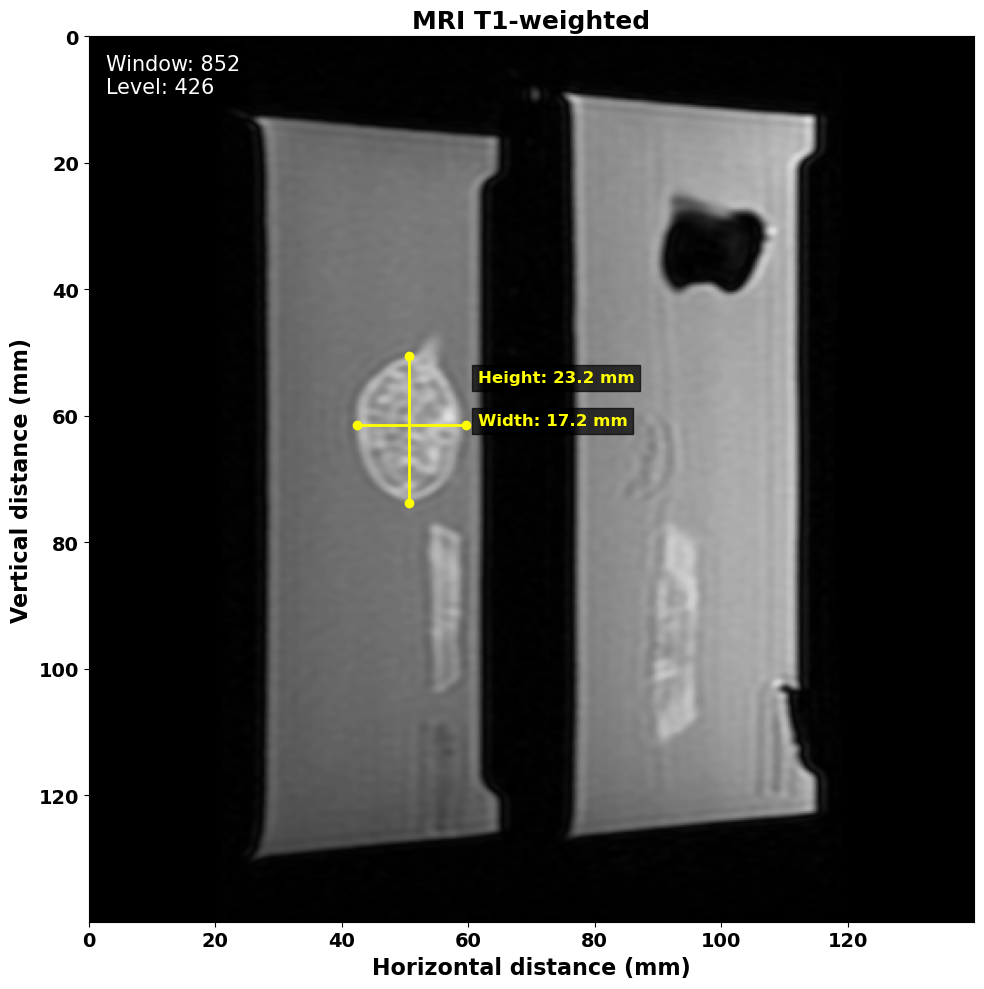

T1 caper — sorted slice 34
Physical position: -15.2327423096 mm
Pixel spacing: [0.2734, 0.2734]
Caper height: 23.2 mm
Caper width: 17.2 mm


In [28]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom

# ==========================================
# LOAD T1 MRI DATA
# ==========================================

folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T1w_6A_6B"
)

files = sorted(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

caper_t1_datasets = [pydicom.dcmread(str(f)) for f in files]

if len({str(ds.SeriesInstanceUID) for ds in caper_t1_datasets}) != 1:
    raise ValueError("The folder contains more than one MRI series.")

# Sort using the same physical-position method as the MRI loader
orientation = np.array(
    caper_t1_datasets[0].ImageOrientationPatient,
    dtype=float
)
normal = np.cross(orientation[:3], orientation[3:])

def slice_position(ds):
    position = np.array(ds.ImagePositionPatient, dtype=float)
    return float(np.dot(position, normal))

caper_t1_datasets.sort(key=slice_position)

# Slice 34: index 33
ds = caper_t1_datasets[33]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)

# Pixel spacing from the selected T1 image
row_mm, col_mm = map(float, ds.PixelSpacing)

# ==========================================
# ORIGINAL MEASUREMENT ENDPOINTS
# ==========================================

top = (185, 185)
bottom = (185, 270)

left = (155, 225)
right = (218, 225)

def distance_mm(p1, p2):
    dx = (p2[0] - p1[0]) * col_mm
    dy = (p2[1] - p1[1]) * row_mm
    return np.hypot(dx, dy)

height_mm = distance_mm(top, bottom)
width_mm = distance_mm(left, right)

# ==========================================
# DISPLAY SETTINGS
# ==========================================

window = 852
level = 426
measurement = True

fig, ax = plt.subplots(figsize=(10, 10))

height, width = image.shape
extent = [0, width * col_mm, height * row_mm, 0]

ax.imshow(
    image,
    cmap="gray",
    vmin=level - window / 2,
    vmax=level + window / 2,
    extent=extent
)

def to_mm(point):
    return point[0] * col_mm, point[1] * row_mm

if measurement:
    for p1, p2 in [(top, bottom), (left, right)]:
        x1, y1 = to_mm(p1)
        x2, y2 = to_mm(p2)

        ax.plot(
            [x1, x2],
            [y1, y2],
            color="yellow",
            linewidth=2,
            marker="o"
        )

    ax.text(
        225 * col_mm, 200 * row_mm,
        f"Height: {height_mm:.1f} mm",
        fontsize=12,
        fontweight="bold",
        color="yellow",
        bbox=dict(facecolor="black", alpha=0.7)
    )

    ax.text(
        225 * col_mm, 225 * row_mm,
        f"Width: {width_mm:.1f} mm",
        fontsize=12,
        fontweight="bold",
        color="yellow",
        bbox=dict(facecolor="black", alpha=0.7)
    )

ax.set_title(
    "MRI T1-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "Horizontal distance (mm)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Vertical distance (mm)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window}\nLevel: {level}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()

fig.savefig(
    "MRI_Caper_T1_Final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("T1 caper — sorted slice 34")
print("Physical position:", slice_position(ds), "mm")
print("Pixel spacing:", ds.PixelSpacing)
print(f"Caper height: {height_mm:.1f} mm")
print(f"Caper width: {width_mm:.1f} mm")

T2 weighted Caper

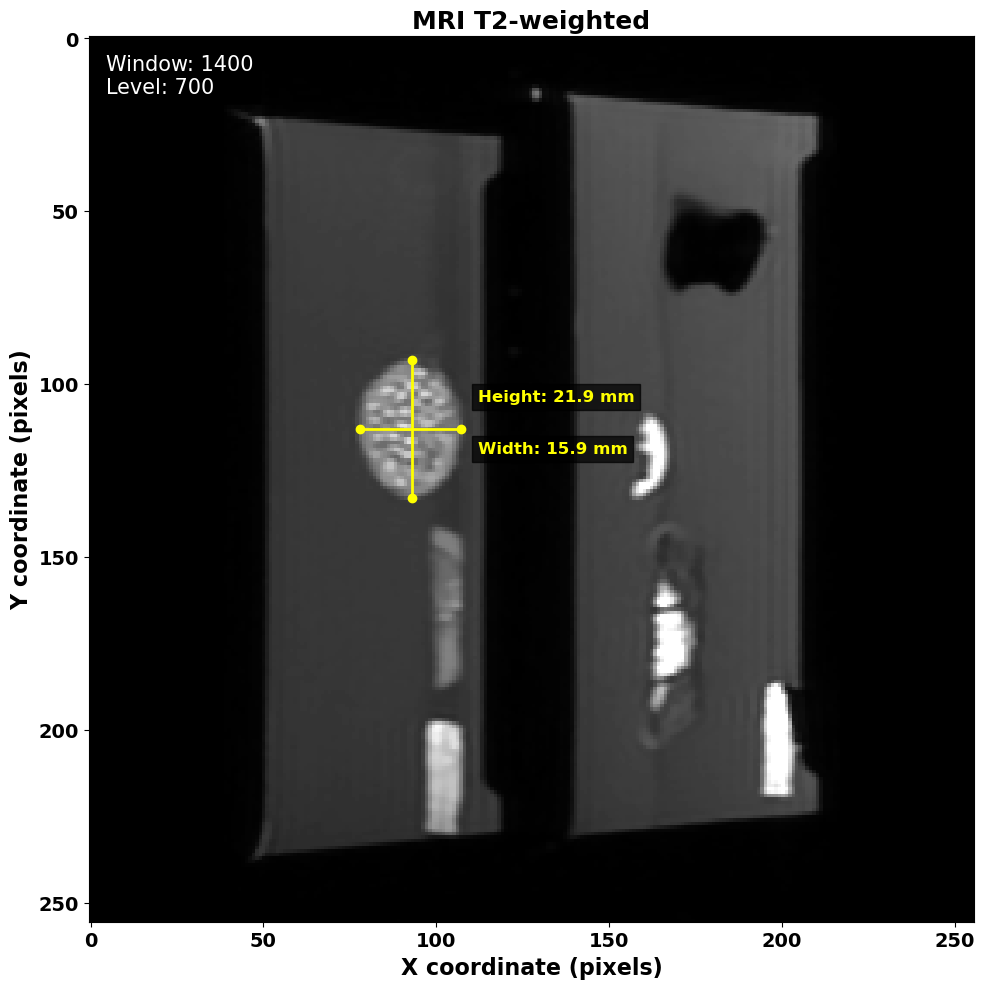

T2 caper — sorted slice 34
Pixel spacing: [0.5469, 0.5469]
Height: 40 pixels = 21.88 mm
Width: 29 pixels = 15.86 mm


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom

# MEASUREMENT TOGGLE
measurement = True

# LOAD T2 MRI DATA
folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T2w_6A_6B"
)

files = sorted(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

caper_t2_datasets = [pydicom.dcmread(str(f)) for f in files]

if len({str(ds.SeriesInstanceUID) for ds in caper_t2_datasets}) != 1:
    raise ValueError("The folder contains more than one MRI series.")

# Preserve the original sorting and slice
caper_t2_datasets.sort(
    key=lambda ds: float(ds.ImagePositionPatient[2])
)

ds = caper_t2_datasets[33]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)

row_mm, col_mm = map(
    float, caper_t2_datasets[0].PixelSpacing
)

# ORIGINAL ENDPOINTS
top = (93, 93)
bottom = (93, 133)
left = (78, 113)
right = (107, 113)

height_px = abs(bottom[1] - top[1])
width_px = abs(right[0] - left[0])

height_mm = height_px * row_mm
width_mm = width_px * col_mm


window = 1400
level = 700

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(
    image,
    cmap="gray",
    vmin=level - window / 2,
    vmax=level + window / 2
)


if measurement:
    ax.plot(
        [top[0], bottom[0]],
        [top[1], bottom[1]],
        color="yellow",
        linewidth=2,
        marker="o"
    )

    ax.plot(
        [left[0], right[0]],
        [left[1], right[1]],
        color="yellow",
        linewidth=2,
        marker="o"
    )

    ax.text(
        112, 105,
        f"Height: {height_mm:.1f} mm",
        color="yellow",
        fontsize=12,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.7)
    )

    ax.text(
        112, 120,
        f"Width: {width_mm:.1f} mm",
        color="yellow",
        fontsize=12,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.7)
    )

ax.set_title(
    "MRI T2-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window}\nLevel: {level}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()
plt.show()

print("T2 caper — sorted slice 34")
print("Pixel spacing:", caper_t2_datasets[0].PixelSpacing)

if measurement:
    print(f"Height: {height_px} pixels = {height_mm:.2f} mm")
    print(f"Width: {width_px} pixels = {width_mm:.2f} mm")

CARROT

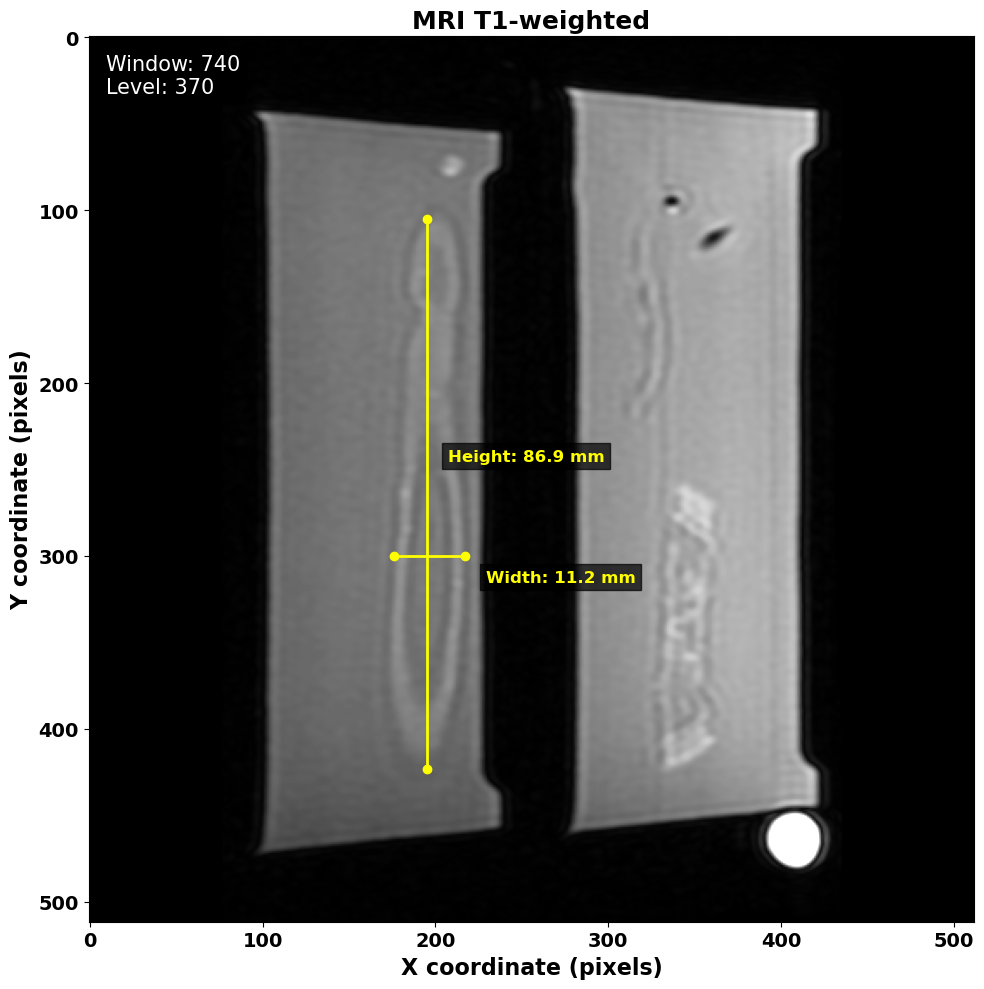

CARROT - T1 MRI
Frame: 78
Physical slice position: 11.167263031
Pixel spacing: [0.2734, 0.2734]
Height endpoints: (195, 105) (195, 423)
Width endpoints: (176, 300) (217, 300)
Height: 318 pixels = 86.9 mm
Width: 41 pixels = 11.2 mm


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom


measurement = True


folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T1w_6A_6B"
)

files = list(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

datasets = [pydicom.dcmread(str(f)) for f in files]

def slice_position(ds):
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    position = np.array(ds.ImagePositionPatient, dtype=float)
    return float(np.dot(position, normal))

datasets.sort(key=slice_position)

# Original carrot slice
frame = 78
ds = datasets[frame - 1]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)

# Original Window / Level
window = 740
level = 370


row_spacing, col_spacing = map(float, ds.PixelSpacing)


x_height = 195
y_top = 105
y_bottom = 423

y_width = 300
x_left = 176
x_right = 217


height_px = abs(y_bottom - y_top)
width_px = abs(x_right - x_left)

height_mm = height_px * row_spacing
width_mm = width_px * col_spacing


fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(
    image,
    cmap="gray",
    vmin=level - window / 2,
    vmax=level + window / 2
)


if measurement:
    ax.plot(
        [x_height, x_height],
        [y_top, y_bottom],
        color="yellow",
        linewidth=2,
        marker="o"
    )

    ax.plot(
        [x_left, x_right],
        [y_width, y_width],
        color="yellow",
        linewidth=2,
        marker="o"
    )

    label_style = dict(
        color="yellow",
        fontsize=12,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.7)
    )

    ax.text(
        x_height + 12, 245,
        f"Height: {height_mm:.1f} mm",
        **label_style
    )

    ax.text(
        x_right + 12, y_width + 15,
        f"Width: {width_mm:.1f} mm",
        **label_style
    )

ax.set_title(
    "MRI T1-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window}\nLevel: {level}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()
plt.show()

# Details for the report
print("CARROT - T1 MRI")
print("Frame:", frame)
print("Physical slice position:", slice_position(ds))
print("Pixel spacing:", ds.PixelSpacing)

if measurement:
    print(
        "Height endpoints:",
        (x_height, y_top),
        (x_height, y_bottom)
    )
    print(
        "Width endpoints:",
        (x_left, y_width),
        (x_right, y_width)
    )
    print(f"Height: {height_px} pixels = {height_mm:.1f} mm")
    print(f"Width: {width_px} pixels = {width_mm:.1f} mm")



CARROT T2

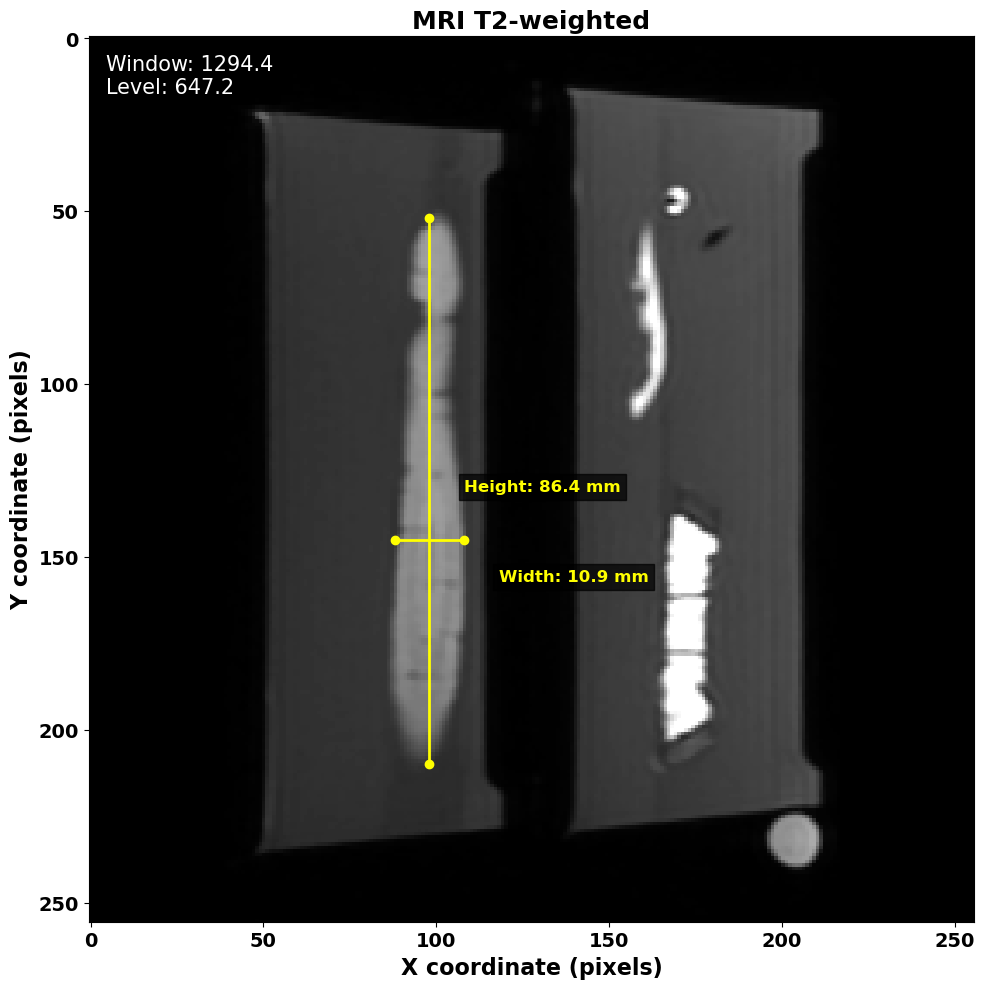

CARROT - T2 MRI
T2 sorted frame: 78
Physical position: 11.1672592163 mm
Pixel spacing: [0.5469, 0.5469]
Height: 158 pixels = 86.4 mm
Width: 20 pixels = 10.9 mm
Height endpoints: (98, 52) (98, 210)
Width endpoints: (88, 145) (108, 145)
Difference from T1 position: 3.814699999438176e-06 mm


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom


measurement = True


folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T2w_6A_6B"
)

files = list(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

datasets = [pydicom.dcmread(str(f)) for f in files]

def slice_position(ds):
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    position = np.array(ds.ImagePositionPatient, dtype=float)
    return float(np.dot(position, normal))

datasets.sort(key=slice_position)

# Original slice selection
target_position = 11.167263031

positions = np.array([slice_position(ds) for ds in datasets])
index = np.argmin(np.abs(positions - target_position))
ds = datasets[index]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)


vmin, vmax = np.percentile(image, [1, 99.2])


window = vmax - vmin
level = (vmax + vmin) / 2


row_spacing, col_spacing = map(float, ds.PixelSpacing)


x_center = 98
y_top = 52
y_bottom = 210

y_width = 145
x_left = 88
x_right = 108


height_pixels = abs(y_bottom - y_top)
width_pixels = abs(x_right - x_left)

height_mm = height_pixels * row_spacing
width_mm = width_pixels * col_spacing


fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(
    image,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)


if measurement:
    ax.plot(
        [x_center, x_center],
        [y_top, y_bottom],
        color="yellow",
        linewidth=2,
        marker="o"
    )

    ax.plot(
        [x_left, x_right],
        [y_width, y_width],
        color="yellow",
        linewidth=2,
        marker="o"
    )

    label_style = dict(
        color="yellow",
        fontsize=12,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.7)
    )

    ax.text(
        x_center + 10, (y_top + y_bottom) / 2,
        f"Height: {height_mm:.1f} mm",
        **label_style
    )

    ax.text(
        x_right + 10, y_width + 12,
        f"Width: {width_mm:.1f} mm",
        **label_style
    )

ax.set_title(
    "MRI T2-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window:.1f}\nLevel: {level:.1f}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()
plt.show()


print("CARROT - T2 MRI")
print("T2 sorted frame:", index + 1)
print("Physical position:", slice_position(ds), "mm")
print("Pixel spacing:", ds.PixelSpacing)

if measurement:
    print(f"Height: {height_pixels} pixels = {height_mm:.1f} mm")
    print(f"Width: {width_pixels} pixels = {width_mm:.1f} mm")
    print(
        "Height endpoints:",
        (x_center, y_top),
        (x_center, y_bottom)
    )
    print(
        "Width endpoints:",
        (x_left, y_width),
        (x_right, y_width)
    )

print(
    "Difference from T1 position:",
    abs(slice_position(ds) - target_position),
    "mm"
)



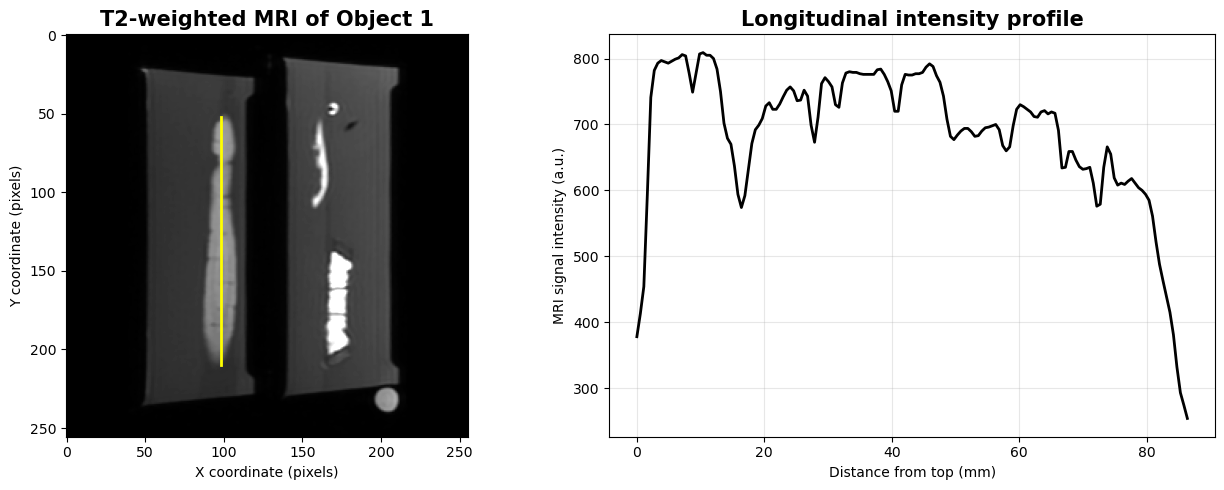

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

x_center = 98
y_top = 52
y_bottom = 210

profile = image[y_top:y_bottom + 1, x_center]
positions_mm = np.arange(len(profile)) * row_spacing

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(
    image,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

axes[0].plot(
    [x_center, x_center],
    [y_top, y_bottom],
    color="yellow",
    linewidth=2
)

axes[0].set_title("T2-weighted MRI of Object 1", fontsize=15, fontweight="bold")
axes[0].set_xlabel("X coordinate (pixels)")
axes[0].set_ylabel("Y coordinate (pixels)")

axes[1].plot(
    positions_mm,
    profile,
    color="black",
    linewidth=2
)

axes[1].set_title("Longitudinal intensity profile", fontsize=15, fontweight="bold")
axes[1].set_xlabel("Distance from top (mm)")
axes[1].set_ylabel("MRI signal intensity (a.u.)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Carrot_T2_intensity_profile.png", dpi=300, bbox_inches="tight")
plt.show()


LEMON SLICE

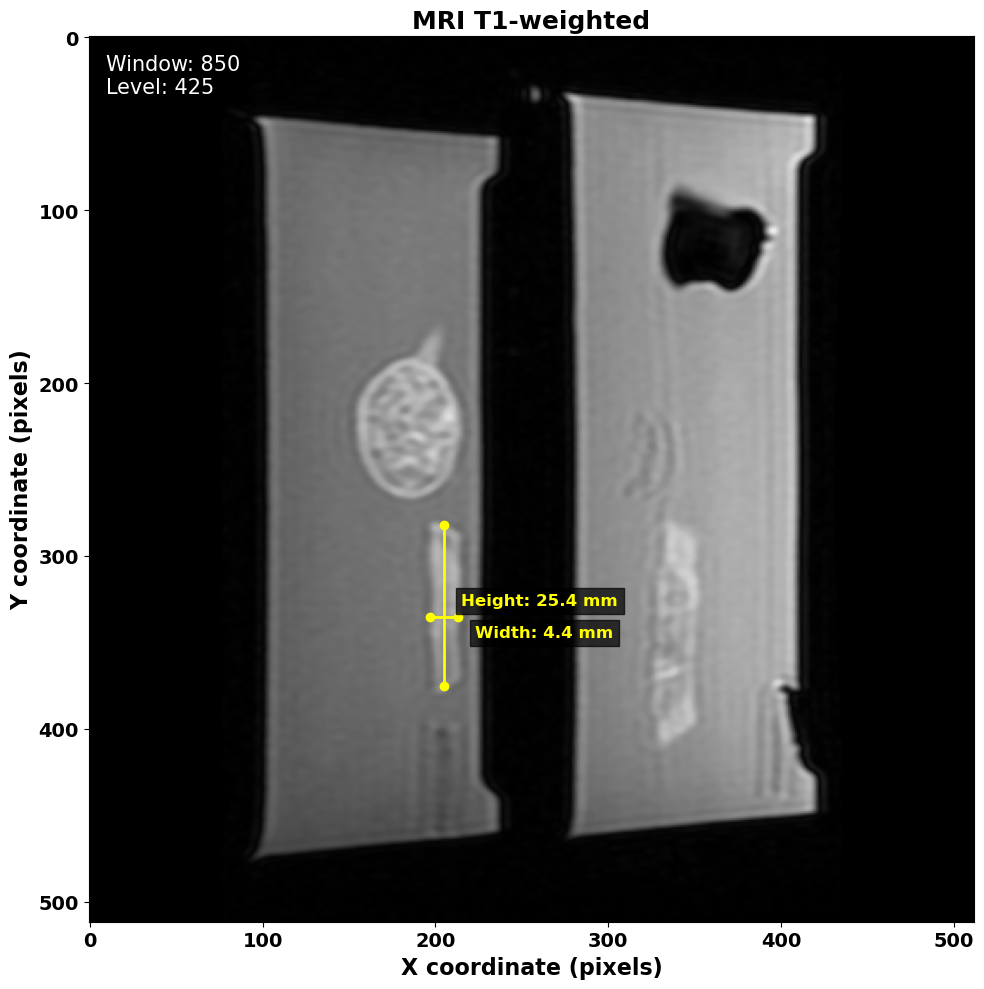

LEMON SLICE - T1 MRI
Sorted frame: 35
Physical position: -14.6327419281 mm
Image dimensions: (512, 512)
Pixel spacing: [0.2734, 0.2734]
Window/Level: 850 / 425
Height: 93 pixels = 25.4 mm
Width: 16 pixels = 4.4 mm
Height endpoints: (205, 282) (205, 375)
Width endpoints: (197, 335) (213, 335)


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom

def plot_mri(
    folder_name,
    object_name,
    weighting,
    target_position,
    window,
    level,
    measurement=True,
    endpoints=None
):
    folder = (
        Path.home()
        / "Desktop/DTU/Semester 5"
        / "22481 Introduction to medical imaging"
        / "Report/MRI data"
        / folder_name
    )

    files = list(folder.rglob("*.dcm"))

    if not files:
        raise FileNotFoundError(f"No DICOM files found in: {folder}")

    datasets = [pydicom.dcmread(str(f)) for f in files]

    def slice_position(ds):
        orientation = np.array(
            ds.ImageOrientationPatient, dtype=float
        )
        normal = np.cross(orientation[:3], orientation[3:])
        position = np.array(ds.ImagePositionPatient, dtype=float)
        return float(np.dot(position, normal))

    datasets.sort(key=slice_position)

    # Preserve the original slice selection
    positions = np.array([slice_position(ds) for ds in datasets])
    index = np.argmin(np.abs(positions - target_position))
    ds = datasets[index]

    image = (
        ds.pixel_array.astype(float)
        * float(getattr(ds, "RescaleSlope", 1))
        + float(getattr(ds, "RescaleIntercept", 0))
    )

    row_spacing, col_spacing = map(float, ds.PixelSpacing)


    fig, ax = plt.subplots(figsize=(10, 10))

    ax.imshow(
        image,
        cmap="gray",
        vmin=level - window / 2,
        vmax=level + window / 2
    )

    if measurement and endpoints is not None:
        (
            x_center,
            y_top,
            y_bottom,
            y_width,
            x_left,
            x_right
        ) = endpoints


        height_pixels = abs(y_bottom - y_top)
        width_pixels = abs(x_right - x_left)

        height_mm = height_pixels * row_spacing
        width_mm = width_pixels * col_spacing

      
        ax.plot(
            [x_center, x_center],
            [y_top, y_bottom],
            color="yellow",
            linewidth=2,
            marker="o"
        )

        ax.plot(
            [x_left, x_right],
            [y_width, y_width],
            color="yellow",
            linewidth=2,
            marker="o"
        )

      
        label_style = dict(
            color="yellow",
            fontsize=12,
            fontweight="bold",
            bbox=dict(facecolor="black", alpha=0.7)
        )

        ax.text(
            x_center + 10, (y_top + y_bottom) / 2,
            f"Height: {height_mm:.1f} mm",
            **label_style
        )

        ax.text(
            x_right + 10, y_width + 12,
            f"Width: {width_mm:.1f} mm",
            **label_style
        )

    ax.set_title(
        f"MRI {weighting}-weighted",
        fontsize=18,
        fontweight="bold"
    )

    ax.set_xlabel(
        "X coordinate (pixels)",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Y coordinate (pixels)",
        fontsize=16,
        fontweight="bold"
    )

    ax.tick_params(axis="both", labelsize=14)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

    # Window / Level annotation
    ax.text(
        0.02, 0.98,
        f"Window: {window}\nLevel: {level}",
        transform=ax.transAxes,
        fontsize=15,
        color="white",
        va="top",
        bbox=dict(facecolor="black", alpha=0.7)
    )

    plt.tight_layout()
    plt.show()

   
    print(f"{object_name.upper()} - {weighting} MRI")
    print("Sorted frame:", index + 1)
    print("Physical position:", slice_position(ds), "mm")
    print("Image dimensions:", image.shape)
    print("Pixel spacing:", ds.PixelSpacing)
    print("Window/Level:", window, "/", level)

    if measurement and endpoints is not None:
        print(
            f"Height: {height_pixels} pixels = {height_mm:.1f} mm"
        )
        print(
            f"Width: {width_pixels} pixels = {width_mm:.1f} mm"
        )
        print(
            "Height endpoints:",
            (x_center, y_top),
            (x_center, y_bottom)
        )
        print(
            "Width endpoints:",
            (x_left, y_width),
            (x_right, y_width)
        )

   

    return ds



lemon_t1 = plot_mri(
    folder_name="3D_T1w_6A_6B",
    object_name="Lemon slice",
    weighting="T1",
    target_position=-14.63,
    window=850,
    level=425,
    measurement=measurement,
    endpoints=(205, 282, 375, 335, 197, 213)
)

LEMON t2w

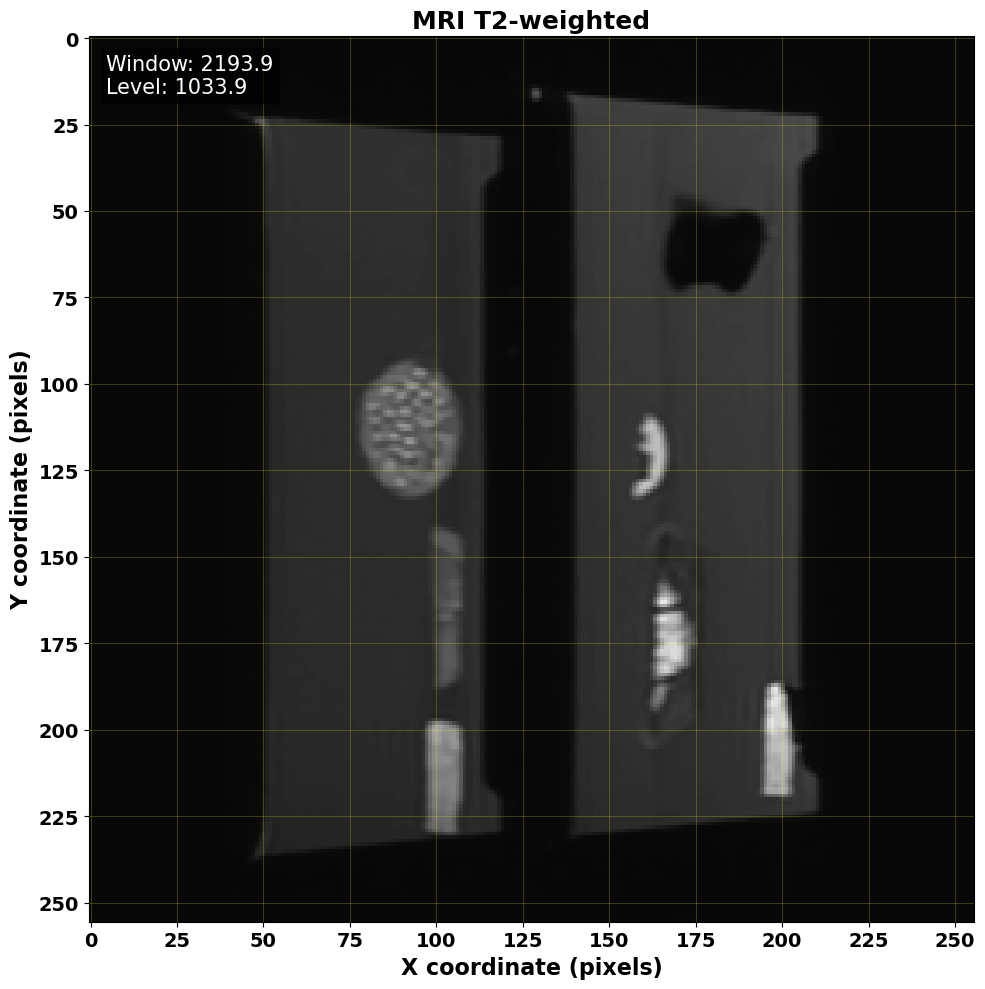

LEMON SLICE - T2 MRI
Sorted frame: 34
Physical position: -15.2327461243 mm
Pixel spacing: [0.5469, 0.5469]
Image dimensions: (256, 256)
Contrast: provisional percentiles [1, 99.2]
Difference from target position: 0.0027461242999997637 mm


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom


folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T2w_6A_6B"
)

files = list(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

lemon_t2_datasets = [pydicom.dcmread(str(f)) for f in files]

def slice_position(ds):
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    position = np.array(ds.ImagePositionPatient, dtype=float)
    return float(np.dot(position, normal))

lemon_t2_datasets.sort(key=slice_position)


target_position = -15.23
positions = np.array([
    slice_position(ds) for ds in lemon_t2_datasets
])

index = np.argmin(np.abs(positions - target_position))
ds = lemon_t2_datasets[index]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)


window = 2193.9
level = 1033.9

vmin = level - window / 2
vmax = level + window / 2

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(image, cmap="gray", vmin=vmin, vmax=vmax)

# Coordinate grid for choosing measurement endpoints
ax.set_xticks(np.arange(0, image.shape[1], 25))
ax.set_yticks(np.arange(0, image.shape[0], 25))
ax.grid(color="yellow", alpha=0.3, linewidth=0.5)

ax.set_title(
    "MRI T2-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window:.1f}\nLevel: {level:.1f}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()
plt.show()

print("LEMON SLICE - T2 MRI")
print("Sorted frame:", index + 1)
print("Physical position:", slice_position(ds), "mm")
print("Pixel spacing:", ds.PixelSpacing)
print("Image dimensions:", image.shape)
print("Contrast: provisional percentiles [1, 99.2]")
print(
    "Difference from target position:",
    abs(slice_position(ds) - target_position),
    "mm"
)

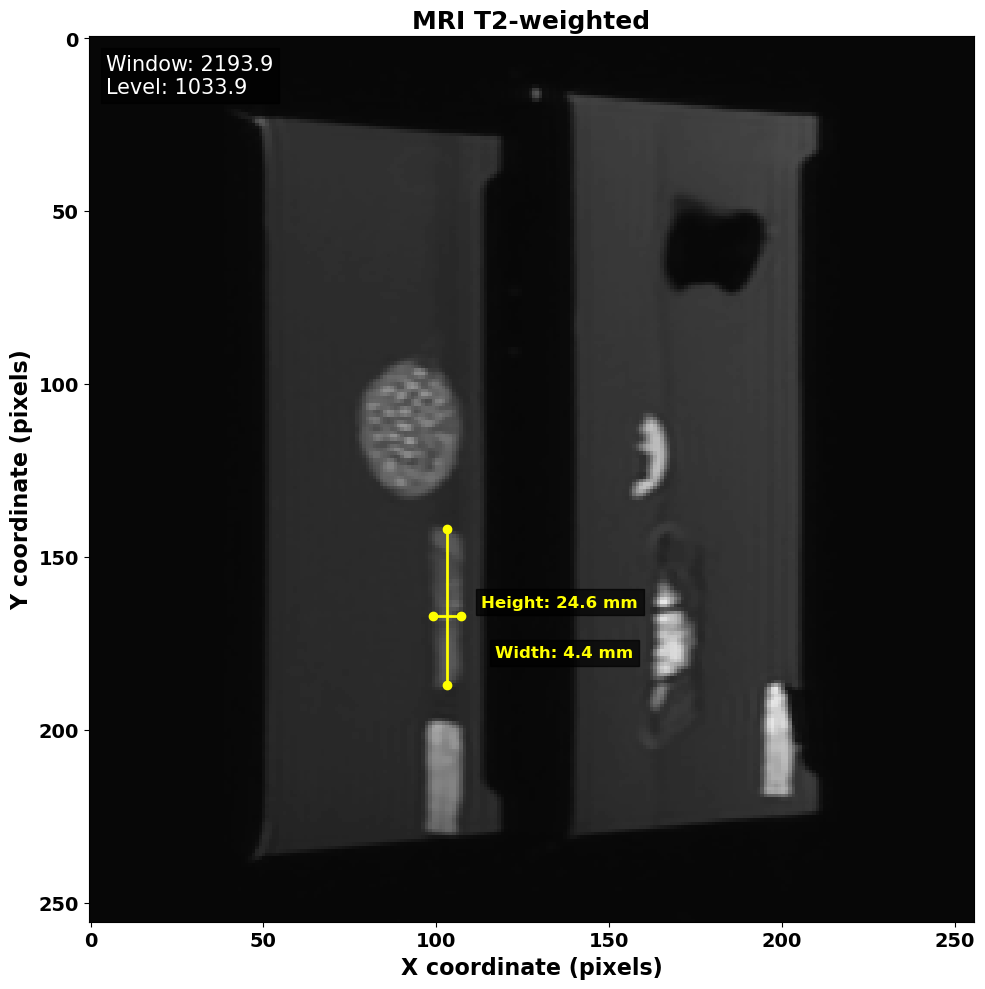

LEMON SLICE - T2 MRI
Sorted frame: 34
Physical position: -15.2327461243 mm
Image dimensions: (256, 256)
Pixel spacing: [0.5469, 0.5469]
Window/Level: 2193.9 / 1033.9
Height: 45 pixels = 24.6 mm
Width: 8 pixels = 4.4 mm
Height endpoints: (103, 142) (103, 187)
Width endpoints: (99, 167) (107, 167)


In [ ]:

measurement = True

lemon_t2 = plot_mri(
    folder_name="3D_T2w_6A_6B",
    object_name="Lemon slice",
    weighting="T2",
    target_position=-15.23,
    window=2193.9,
    level=1033.9,
    measurement=measurement,
    endpoints=(103, 142, 187, 167, 99, 107)
)

LASt object

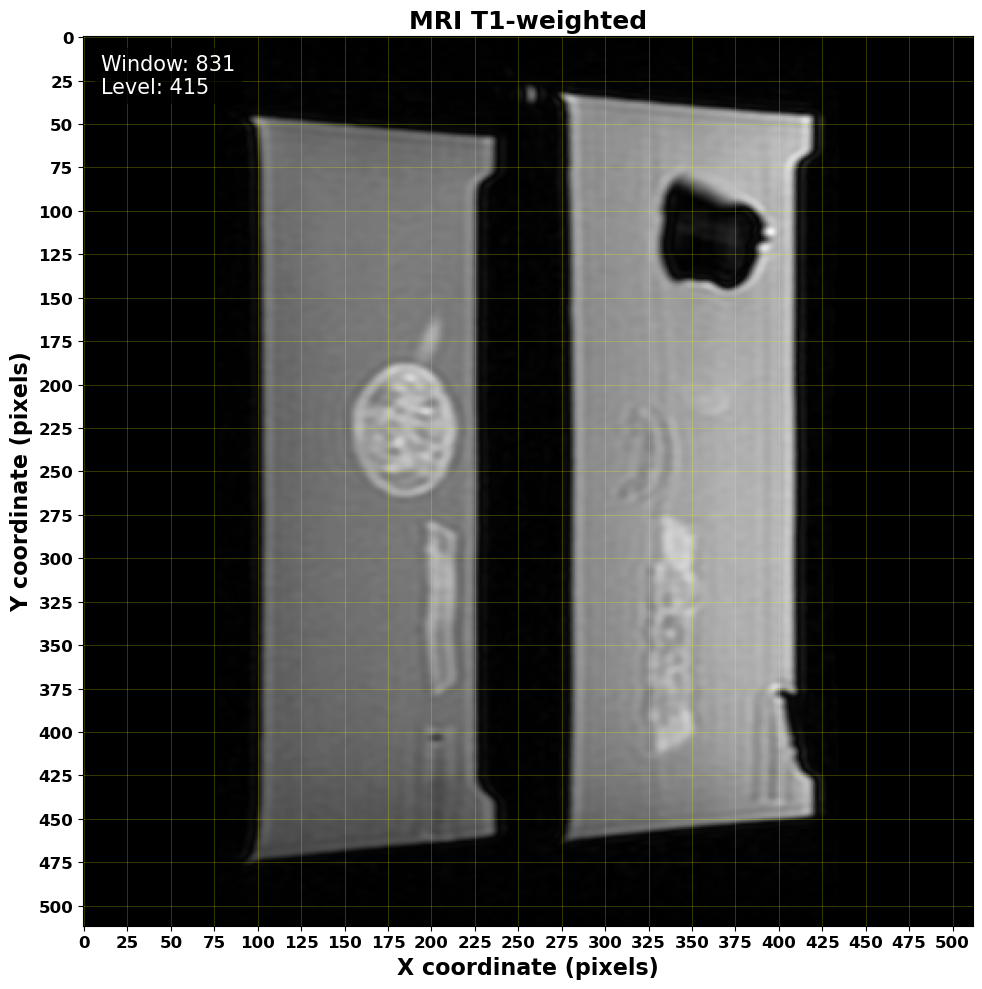

LAST OBJECT - T1 MRI
Sorted frame: 37
Physical position: -13.4327411652 mm
Pixel spacing: [0.2734, 0.2734]
Window/Level: 831 / 415


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom


folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T1w_6A_6B"
)

files = list(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

last_object_datasets = [pydicom.dcmread(str(f)) for f in files]

def slice_position(ds):
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    position = np.array(ds.ImagePositionPatient, dtype=float)
    return float(np.dot(position, normal))

last_object_datasets.sort(key=slice_position)

# Match the physical position shown in Weasis
target_position = -13.43

positions = np.array([
    slice_position(ds) for ds in last_object_datasets
])

index = np.argmin(np.abs(positions - target_position))
ds = last_object_datasets[index]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)

# Window / Level from Weasis
window = 831
level = 415

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(
    image,
    cmap="gray",
    vmin=level - window / 2,
    vmax=level + window / 2
)


ax.set_xticks(np.arange(0, image.shape[1], 25))
ax.set_yticks(np.arange(0, image.shape[0], 25))
ax.grid(color="yellow", alpha=0.3, linewidth=0.5)

ax.set_title(
    "MRI T1-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=12)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window}\nLevel: {level}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()
plt.show()

print("LAST OBJECT - T1 MRI")
print("Sorted frame:", index + 1)
print("Physical position:", slice_position(ds), "mm")
print("Pixel spacing:", ds.PixelSpacing)
print("Window/Level:", window, "/", level)

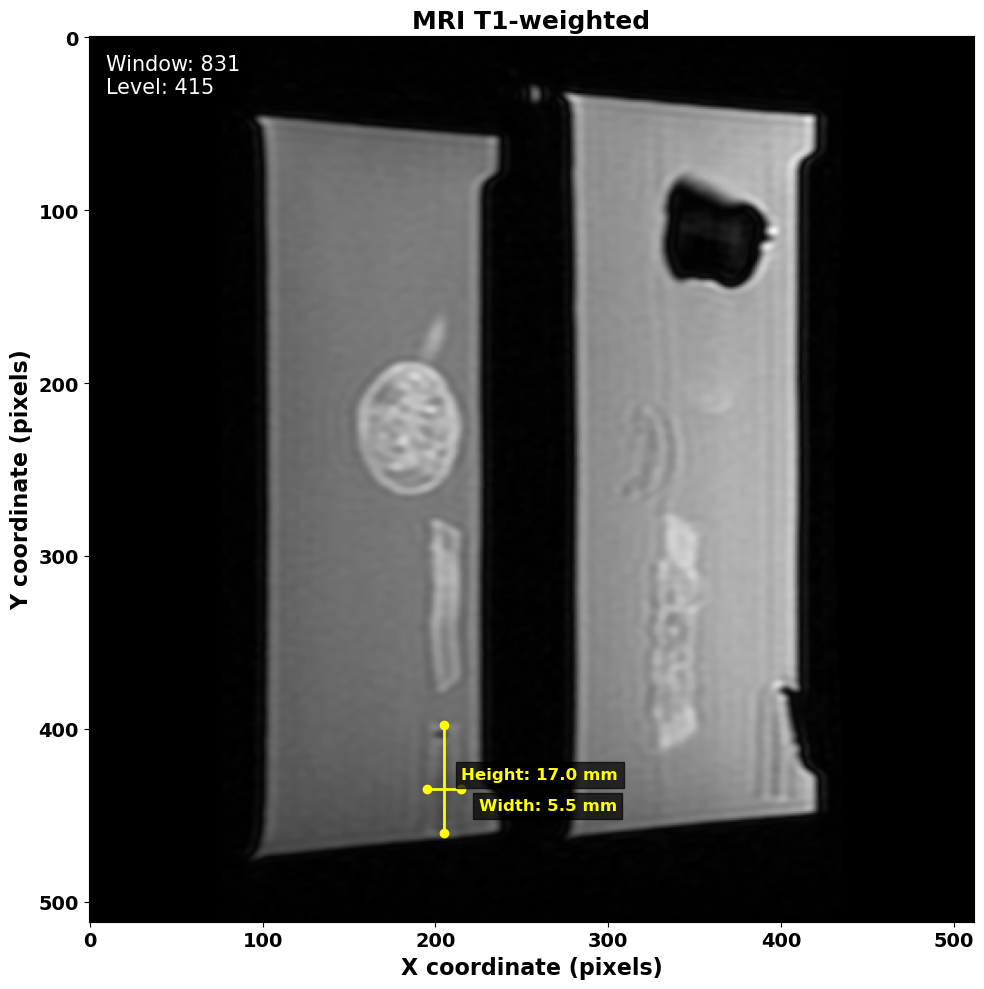

LAST OBJECT - T1 MRI
Sorted frame: 37
Physical position: -13.4327411652 mm
Image dimensions: (512, 512)
Pixel spacing: [0.2734, 0.2734]
Window/Level: 831 / 415
Height: 62 pixels = 17.0 mm
Width: 20 pixels = 5.5 mm
Height endpoints: (205, 398) (205, 460)
Width endpoints: (195, 435) (215, 435)


In [ ]:

measurement = True

last_object_t1 = plot_mri(
    folder_name="3D_T1w_6A_6B",
    object_name="Last object",
    weighting="T1",
    target_position=-13.43,
    window=831,
    level=415,
    measurement=measurement,
    endpoints=(
        205,  # x_center
        398,  # y_top
        460,  # y_bottom
        435,  # y_width
        195,  # x_left
        215   # x_right
    )
)

LAS TBOBJECT t2w

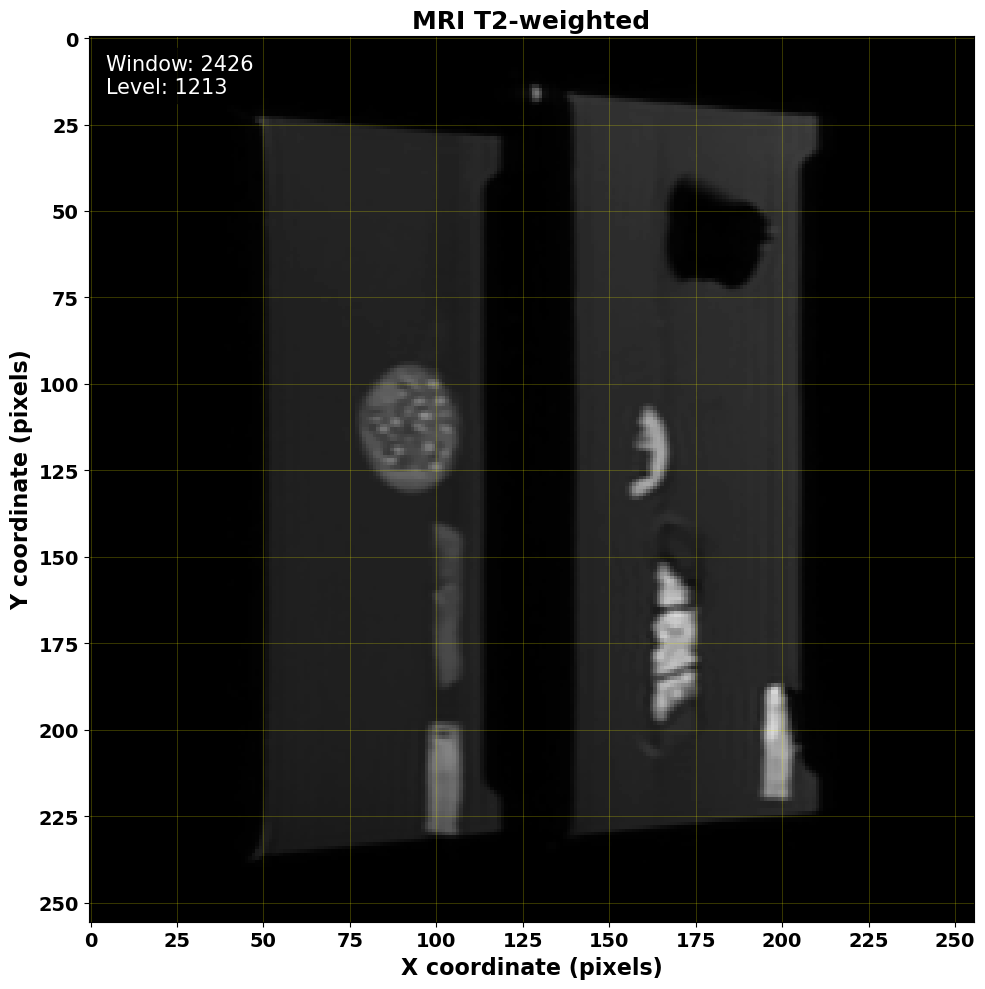

LAST OBJECT - T2 MRI
Sorted frame: 37
Physical position: -13.4327449799 mm
Pixel spacing: [0.5469, 0.5469]
Difference from T1 target: 0.002744979900000999 mm


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom


folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T2w_6A_6B"
)

files = list(folder.rglob("*.dcm"))

if not files:
    raise FileNotFoundError(f"No DICOM files found in: {folder}")

last_object_t2_datasets = [
    pydicom.dcmread(str(f)) for f in files
]

def slice_position(ds):
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    position = np.array(ds.ImagePositionPatient, dtype=float)
    return float(np.dot(position, normal))

last_object_t2_datasets.sort(key=slice_position)


target_position = -13.43

positions = np.array([
    slice_position(ds) for ds in last_object_t2_datasets
])

index = np.argmin(np.abs(positions - target_position))
ds = last_object_t2_datasets[index]

image = (
    ds.pixel_array.astype(float)
    * float(getattr(ds, "RescaleSlope", 1))
    + float(getattr(ds, "RescaleIntercept", 0))
)


window = 2426
level = 1213

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(
    image,
    cmap="gray",
    vmin=level - window / 2,
    vmax=level + window / 2
)


ax.set_xticks(np.arange(0, image.shape[1], 25))
ax.set_yticks(np.arange(0, image.shape[0], 25))
ax.grid(color="yellow", alpha=0.3, linewidth=0.5)

ax.set_title(
    "MRI T2-weighted",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.02, 0.98,
    f"Window: {window}\nLevel: {level}",
    transform=ax.transAxes,
    fontsize=15,
    color="white",
    va="top",
    bbox=dict(facecolor="black", alpha=0.7)
)

plt.tight_layout()
plt.show()

print("LAST OBJECT - T2 MRI")
print("Sorted frame:", index + 1)
print("Physical position:", slice_position(ds), "mm")
print("Pixel spacing:", ds.PixelSpacing)
print(
    "Difference from T1 target:",
    abs(slice_position(ds) - target_position),
    "mm"
)

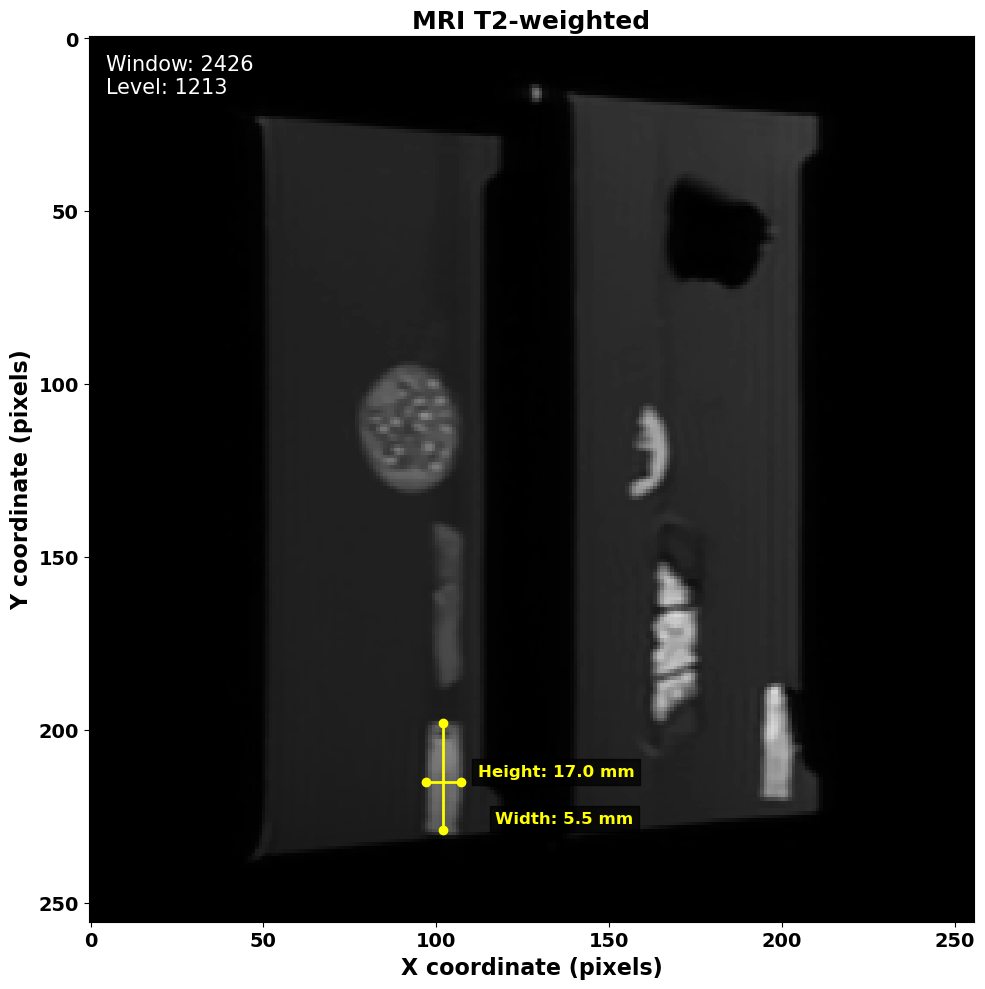

LAST OBJECT - T2 MRI
Sorted frame: 37
Physical position: -13.4327449799 mm
Image dimensions: (256, 256)
Pixel spacing: [0.5469, 0.5469]
Window/Level: 2426 / 1213
Height: 31 pixels = 17.0 mm
Width: 10 pixels = 5.5 mm
Height endpoints: (102, 198) (102, 229)
Width endpoints: (97, 215) (107, 215)


In [ ]:

measurement = True

last_object_t2 = plot_mri(
    folder_name="3D_T2w_6A_6B",
    object_name="Last object",
    weighting="T2",
    target_position=-13.43,
    window=2426,
    level=1213,
    measurement=measurement,
    endpoints=(
        102,  # x_center
        198,  # y_top
        229,  # y_bottom
        215,  # y_width
        97,   # x_left
        107   # x_right
    )
)

In [ ]:
from pathlib import Path
import pydicom

base_folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data"
)

for weighting, folder_name in [
    ("T1", "3D_T1w_6A_6B"),
    ("T2", "3D_T2w_6A_6B")
]:
    files = sorted((base_folder / folder_name).rglob("*.dcm"))

    if not files:
        print(f"{weighting}: No DICOM files found")
        continue

    # Check whether acquisition settings vary across the series
    settings = set()

    for file in files:
        ds = pydicom.dcmread(str(file), stop_before_pixels=True)
        settings.add((
            str(ds.get("EchoTime", "Not recorded")),
            str(ds.get("RepetitionTime", "Not recorded")),
            str(ds.get("FlipAngle", "Not recorded"))
        ))

    print(f"\n{weighting}-weighted MRI")
    for te, tr, fa in sorted(settings):
        print(f"TE: {te} ms | TR: {tr} ms | FA: {fa}°")

    if len(settings) > 1:
        print("Multiple settings found—check the selected image.")


T1-weighted MRI
TE: 9.526 ms | TR: 999 ms | FA: 90.0°

T2-weighted MRI
TE: 94.991 ms | TR: 4303 ms | FA: 90.0°


In [ ]:
def show_metadata(ds, arr):
    """Print image dimensions and metadata needed to judge measurement validity."""
    print("Array shape:", arr.shape)
    for field in ["Modality", "SeriesDescription", "PixelSpacing", "SliceThickness", "SpacingBetweenSlices", "PhotometricInterpretation", "RescaleSlope", "RescaleIntercept"]:
        print(f"{field}: {getattr(ds, field, 'not provided')}")
    print("WARNING: confirm image geometry, pixel calibration, and orientation before physical measurements.")

In [ ]:
show_metadata(last_object_t1, last_object_t1.pixel_array)

Array shape: (512, 512)
Modality: MR
SeriesDescription: 3D T1w - 6A + 6B
PixelSpacing: [0.2734, 0.2734]
SliceThickness: 1.2
SpacingBetweenSlices: 0.6
PhotometricInterpretation: MONOCHROME2
RescaleSlope: not provided
RescaleIntercept: not provided


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from ipywidgets import interact, IntSlider


mpr_folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T1w_6A_6B"
)

mpr_files = sorted(mpr_folder.rglob("*.dcm"))
if not mpr_files:
    raise FileNotFoundError(f"No DICOM files found in {mpr_folder}")

mpr_datasets = [pydicom.dcmread(f) for f in mpr_files]

if len({str(ds.SeriesInstanceUID) for ds in mpr_datasets}) != 1:
    raise ValueError("This folder contains more than one series.")


mpr_orientation = np.asarray(
    mpr_datasets[0].ImageOrientationPatient, dtype=float
)
mpr_col_direction = mpr_orientation[:3]
mpr_row_direction = mpr_orientation[3:]
mpr_normal = np.cross(mpr_col_direction, mpr_row_direction)

for ds in mpr_datasets:
    if not np.allclose(
        ds.ImageOrientationPatient, mpr_orientation, atol=1e-5
    ):
        raise ValueError("The images have different orientations.")


mpr_datasets.sort(
    key=lambda ds: np.dot(
        np.asarray(ds.ImagePositionPatient, dtype=float),
        mpr_normal
    )
)

mpr_positions = np.array([
    np.asarray(ds.ImagePositionPatient, dtype=float)
    for ds in mpr_datasets
])

mpr_gaps = np.diff(mpr_positions @ mpr_normal)
mpr_slice_spacing = float(np.median(mpr_gaps))

if mpr_slice_spacing <= 0 or not np.allclose(
    mpr_gaps, mpr_slice_spacing, atol=0.01
):
    raise ValueError("Duplicate slices or irregular slice spacing found.")

if not np.allclose(
    np.diff(mpr_positions, axis=0),
    mpr_slice_spacing * mpr_normal,
    atol=0.01
):
    raise ValueError("This series requires additional geometric resampling.")

mpr_pixel_spacing = np.asarray(
    mpr_datasets[0].PixelSpacing, dtype=float
)
for ds in mpr_datasets:
    if not np.allclose(ds.PixelSpacing, mpr_pixel_spacing):
        raise ValueError("Pixel spacing changes within the series.")


mpr_volume = np.stack([
    ds.pixel_array.astype(np.float32)
    * float(ds.get("RescaleSlope", 1))
    + float(ds.get("RescaleIntercept", 0))
    for ds in mpr_datasets
])


mpr_directions = np.array([
    mpr_normal, mpr_row_direction, mpr_col_direction
])
mpr_axis_ids = np.argmax(np.abs(mpr_directions), axis=1)

if (
    len(set(mpr_axis_ids)) != 3
    or not np.allclose(
        np.abs(mpr_directions),
        np.eye(3)[mpr_axis_ids],
        atol=1e-4
    )
):
    raise ValueError("Oblique acquisition: a resampling step is needed.")


mpr_order = [
    int(np.where(mpr_axis_ids == axis)[0][0])
    for axis in (2, 1, 0)
]
mpr_volume = np.transpose(mpr_volume, mpr_order)

mpr_original_spacing = np.array([
    mpr_slice_spacing, *mpr_pixel_spacing
])
mpr_sz, mpr_sy, mpr_sx = mpr_original_spacing[mpr_order]

for new_axis, old_axis in enumerate(mpr_order):
    direction = mpr_directions[old_axis, mpr_axis_ids[old_axis]]
    if direction < 0:
        mpr_volume = np.flip(mpr_volume, axis=new_axis)

mpr_nz, mpr_ny, mpr_nx = mpr_volume.shape

print(f"Loaded {len(mpr_datasets)} T1 slices")
print(f"Distance between slice centres: {mpr_slice_spacing:.3f} mm")


# Display settings: change these later if needed
mpr_window = 850
mpr_level = 425

def show_mpr(axial, coronal, sagittal):
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))

    views = [
        (
            mpr_volume[axial, :, :],
            "Axial", "upper", mpr_sy / mpr_sx
        ),
        (
            mpr_volume[:, coronal, :],
            "Coronal", "lower", mpr_sz / mpr_sx
        ),
        (
            mpr_volume[:, :, sagittal],
            "Sagittal", "lower", mpr_sz / mpr_sy
        ),
    ]

    for ax, (image, title, origin, aspect) in zip(axes, views):
        ax.imshow(
            image,
            cmap="gray",
            origin=origin,
            aspect=aspect,
            interpolation="nearest",
            vmin=mpr_level - mpr_window / 2,
            vmax=mpr_level + mpr_window / 2,
        )
        ax.set_title(f"T1-weighted MRI — {title}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


interact(
    show_mpr,
    axial=IntSlider(
        min=0, max=mpr_nz - 1, value=mpr_nz // 2,
        description="Axial", continuous_update=False
    ),
    coronal=IntSlider(
        min=0, max=mpr_ny - 1, value=mpr_ny // 2,
        description="Coronal", continuous_update=False
    ),
    sagittal=IntSlider(
        min=0, max=mpr_nx - 1, value=mpr_nx // 2,
        description="Sagittal", continuous_update=False
    ),
);

Loaded 120 T1 slices
Distance between slice centres: 0.600 mm


interactive(children=(IntSlider(value=256, continuous_update=False, description='Axial', max=511), IntSlider(v…

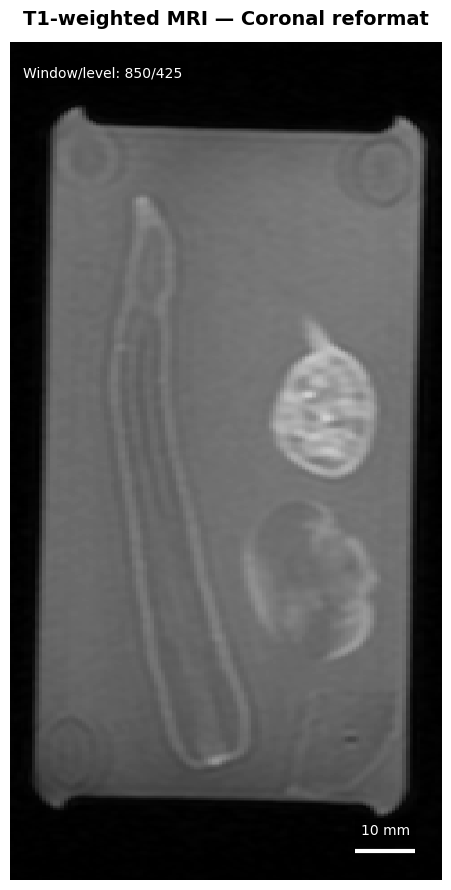

Saved to: /Users/liv_bechet/Desktop/DTU/Semester 5/22481 Introduction to medical imaging/Report/MRI data/MRI_T1_coronal.png


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

coronal_index = 196
window = 850
level = 425

coronal_image = mpr_volume[:, coronal_index, :]

# Physical dimensions of the displayed image
height_mm = coronal_image.shape[0] * mpr_sz
width_mm = coronal_image.shape[1] * mpr_sx

fig, ax = plt.subplots(figsize=(6, 9))

ax.imshow(
    coronal_image,
    cmap="gray",
    origin="lower",
    extent=(0, width_mm, 0, height_mm),
    aspect="equal",
    interpolation="nearest",
    vmin=level - window / 2,
    vmax=level + window / 2,
)

ax.set_title(
    "T1-weighted MRI — Coronal reformat",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

# Display settings
ax.text(
    0.03, 0.97,
    f"Window/level: {window}/{level}",
    transform=ax.transAxes,
    color="white",
    fontsize=10,
    va="top",
    bbox=dict(facecolor="black", alpha=0.6, edgecolor="none"),
)


bar_length = 10
bar_right = width_mm * 0.94
bar_left = bar_right - bar_length
bar_y = height_mm * 0.035

ax.plot(
    [bar_left, bar_right],
    [bar_y, bar_y],
    color="white",
    linewidth=3,
    solid_capstyle="butt",
)

ax.text(
    (bar_left + bar_right) / 2,
    bar_y + height_mm * 0.015,
    "10 mm",
    color="white",
    fontsize=10,
    ha="center",
    va="bottom",
    bbox=dict(facecolor="black", alpha=0.6, edgecolor="none"),
)

ax.axis("off")
fig.tight_layout()


output_path = mpr_folder.parent / "MRI_T1_coronal.png"
fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
print(f"Saved to: {output_path}")

POSSIBLE MUSHROOM — T1 MRI
Height: 26.0 mm
Width: 23.0 mm


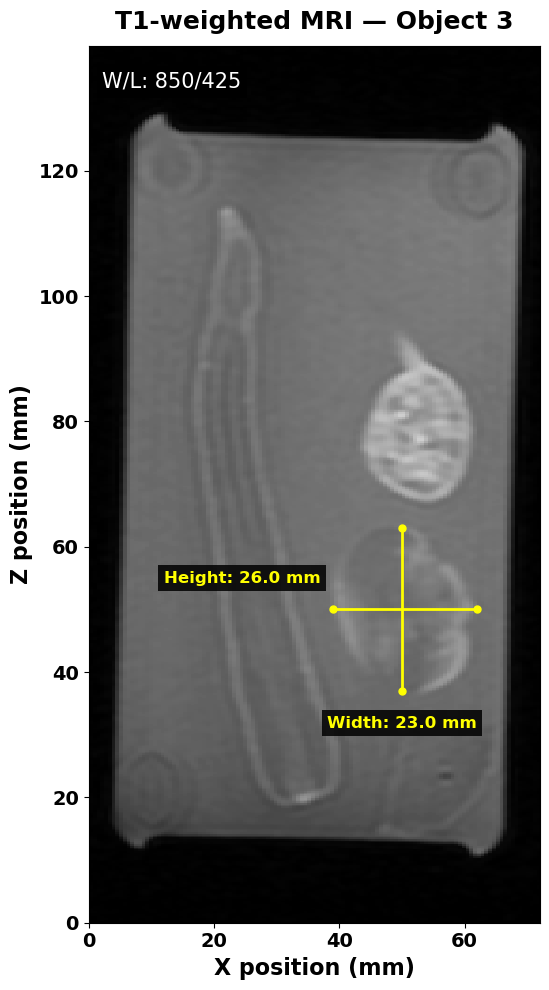

Saved to: /Users/liv_bechet/Desktop/DTU/Semester 5/22481 Introduction to medical imaging/Report/MRI data/T1_weighted_object_3_measured.png


In [ ]:
import matplotlib.pyplot as plt

measurement = True

coronal_index = 196
window = 850
level = 425

coronal_image = mpr_volume[:, coronal_index, :]

height_mm = coronal_image.shape[0] * mpr_sz
width_mm = coronal_image.shape[1] * mpr_sx

top = (50, 63)
bottom = (50, 37)
left = (39, 50)
right = (62, 50)

fig, ax = plt.subplots(figsize=(7, 10))

ax.imshow(
    coronal_image,
    cmap="gray",
    origin="lower",
    extent=(0, width_mm, 0, height_mm),
    aspect="equal",
    interpolation="nearest",
    vmin=level - window / 2,
    vmax=level + window / 2,
)

ax.set_title(
    "T1-weighted MRI — Object 3",
    fontsize=18,
    fontweight="bold",
    pad=12
)

ax.set_xlabel("X position (mm)", fontsize=16, fontweight="bold")
ax.set_ylabel("Z position (mm)", fontsize=16, fontweight="bold")
ax.tick_params(axis="both", labelsize=14)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.text(
    0.03, 0.97,
    f"W/L: {window}/{level}",
    transform=ax.transAxes,
    color="white",
    fontsize=15,
    va="top",
    bbox=dict(
        facecolor="black",
        alpha=0.85,
        edgecolor="none",
        pad=4
    )
)

if measurement:
    mushroom_height = abs(top[1] - bottom[1])
    mushroom_width = abs(right[0] - left[0])

    ax.plot(
        [top[0], bottom[0]],
        [top[1], bottom[1]],
        color="yellow",
        linewidth=2,
        marker="o",
        markersize=5
    )

    ax.plot(
        [left[0], right[0]],
        [left[1], right[1]],
        color="yellow",
        linewidth=2,
        marker="o",
        markersize=5
    )

    label_style = dict(
        color="yellow",
        fontsize=12,
        fontweight="bold",
        bbox=dict(
            facecolor="black",
            alpha=0.85,
            edgecolor="none",
            pad=4
        )
    )

    ax.text(
        37, 55,
        f"Height: {mushroom_height:.1f} mm",
        ha="right",
        va="center",
        **label_style
    )

    ax.text(
        50, 33,
        f"Width: {mushroom_width:.1f} mm",
        ha="center",
        va="top",
        **label_style
    )

    print("POSSIBLE MUSHROOM — T1 MRI")
    print(f"Height: {mushroom_height:.1f} mm")
    print(f"Width: {mushroom_width:.1f} mm")

plt.tight_layout()

output_path = mpr_folder.parent / (
    "T1_weighted_object_3_measured.png"
    if measurement
    else "T1_weighted_object_3.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved to: {output_path}")

T1 volume ready: (512, 512, 120)
Spacing (z, y, x): (0.2734, 0.2734, 0.600000381400001) mm


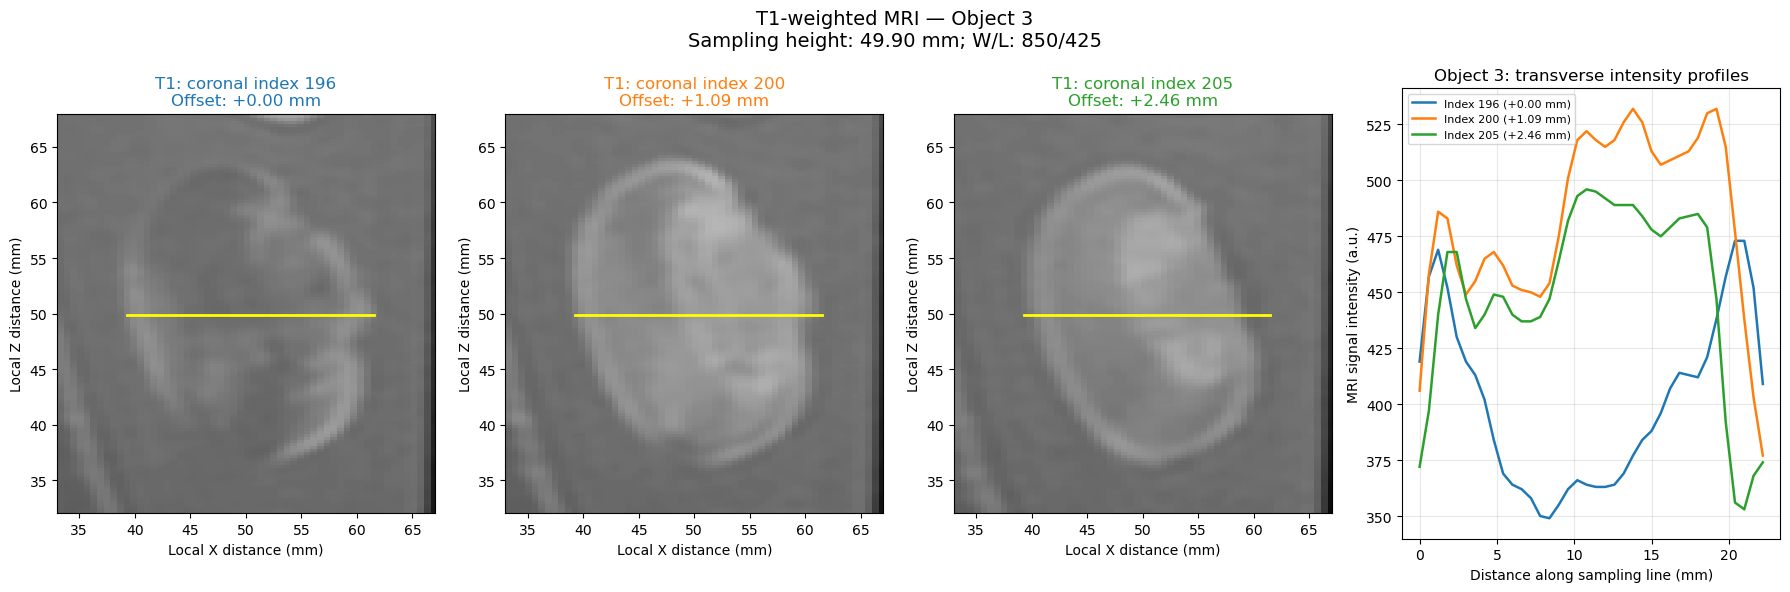

Coronal indices are zero-based.
Spacing between coronal planes: 0.2734 mm
Sampling interval along each line: 0.6000 mm
Profiles use one row of voxels, without smoothing.


In [ ]:
from pathlib import Path
import numpy as np
import pydicom


folder = (
    Path.home()
    / "Desktop/DTU/Semester 5"
    / "22481 Introduction to medical imaging"
    / "Report/MRI data/3D_T1w_6A_6B"
)

files = sorted(
    f for f in folder.rglob("*.dcm")
    if not f.name.startswith("._")
    and "__MACOSX" not in f.parts
)

if not files:
    raise FileNotFoundError(f"No DICOM images found in: {folder}")

datasets = [pydicom.dcmread(str(f)) for f in files]

if len({str(ds.SeriesInstanceUID) for ds in datasets}) != 1:
    raise ValueError("The folder must contain exactly one MRI series.")

if len(datasets) < 2:
    raise ValueError("At least two slices are needed.")

orientation = np.asarray(
    datasets[0].ImageOrientationPatient, dtype=float
)
column_direction = orientation[:3]
row_direction = orientation[3:]
normal = np.cross(column_direction, row_direction)

spacing = np.asarray(datasets[0].PixelSpacing, dtype=float)

for ds in datasets:
    if not np.allclose(
        ds.ImageOrientationPatient, orientation, atol=1e-5
    ):
        raise ValueError("The images have different orientations.")
    if not np.allclose(ds.PixelSpacing, spacing):
        raise ValueError("Pixel spacing changes between images.")

datasets.sort(
    key=lambda ds: np.dot(
        np.asarray(ds.ImagePositionPatient, dtype=float),
        normal,
    )
)

positions = np.array([
    np.asarray(ds.ImagePositionPatient, dtype=float)
    for ds in datasets
])

gaps = np.diff(positions @ normal)
slice_spacing = float(np.median(gaps))

if (
    np.any(gaps <= 0)
    or not np.allclose(gaps, slice_spacing, atol=0.01)
):
    raise ValueError("Duplicate slices or uneven slice spacing.")

if not np.allclose(
    np.diff(positions, axis=0),
    slice_spacing * normal,
    atol=0.01,
):
    raise ValueError("This acquisition requires geometric resampling.")

volume = np.stack([
    ds.pixel_array.astype(np.float32)
    * float(ds.get("RescaleSlope", 1))
    + float(ds.get("RescaleIntercept", 0))
    for ds in datasets
])

# Original array axes: slice, row, column
directions = np.array([
    normal, row_direction, column_direction
])
axis_ids = np.argmax(np.abs(directions), axis=1)

if (
    len(set(axis_ids)) != 3
    or not np.allclose(
        np.abs(directions),
        np.eye(3)[axis_ids],
        atol=1e-4,
    )
):
    raise ValueError("Oblique images require a different reformat method.")


order = [
    int(np.where(axis_ids == axis)[0][0])
    for axis in (2, 1, 0)
]

mpr_volume = np.transpose(volume, order)
original_spacing = np.array([slice_spacing, *spacing])
mpr_sz, mpr_sy, mpr_sx = original_spacing[order]

for new_axis, old_axis in enumerate(order):
    if directions[old_axis, axis_ids[old_axis]] < 0:
        mpr_volume = np.flip(mpr_volume, axis=new_axis)

print("T1 volume ready:", mpr_volume.shape)
print(
    "Spacing (z, y, x):",
    (mpr_sz, mpr_sy, mpr_sx),
    "mm",
)

import numpy as np
import matplotlib.pyplot as plt


slice_indices = [196, 200, 205]


line_z_mm = 50.0
x_start_mm = 39.0
x_end_mm = 62.0

window = 850
level = 425

nz, ny, nx = mpr_volume.shape

if any(i < 0 or i >= ny for i in slice_indices):
    raise ValueError(f"Coronal indices must be between 0 and {ny - 1}.")


x_centres = (np.arange(nx) + 0.5) * mpr_sx
z_centres = (np.arange(nz) + 0.5) * mpr_sz

if not z_centres[0] <= line_z_mm <= z_centres[-1]:
    raise ValueError("The sampling line is outside the image.")

z_index = int(np.argmin(np.abs(z_centres - line_z_mm)))
selected_x = np.flatnonzero(
    (x_centres >= x_start_mm) & (x_centres <= x_end_mm)
)

if len(selected_x) < 2:
    raise ValueError("The selected line contains fewer than two pixels.")


sample_x = x_centres[selected_x]
sample_z = z_centres[z_index]
distance_mm = sample_x - sample_x[0]

colours = ["tab:blue", "tab:orange", "tab:green"]
reference_index = 196

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for ax, index, colour in zip(axes[:3], slice_indices, colours):
    image = mpr_volume[:, index, :]

    ax.imshow(
        image,
        cmap="gray",
        origin="lower",
        extent=(0, nx * mpr_sx, 0, nz * mpr_sz),
        aspect="equal",
        interpolation="nearest",
        vmin=level - window / 2,
        vmax=level + window / 2,
    )

    ax.plot(
        [sample_x[0], sample_x[-1]],
        [sample_z, sample_z],
        color="yellow",
        linewidth=2,
    )

    ax.set_xlim(33, 67)
    ax.set_ylim(32, 68)

    offset_mm = (index - reference_index) * mpr_sy

    ax.set_title(
        f"T1: coronal index {index}\n"
        f"Offset: {offset_mm:+.2f} mm",
        color=colour,
    )
    ax.set_xlabel("Local X distance (mm)")
    ax.set_ylabel("Local Z distance (mm)")

    # Extract a single row from the original volume.
    # No smoothing or averaging is applied.
    profile = image[z_index, selected_x]

    axes[3].plot(
        distance_mm,
        profile,
        color=colour,
        linewidth=1.8,
        label=f"Index {index} ({offset_mm:+.2f} mm)",
    )

axes[3].set_title("Object 3: transverse intensity profiles")
axes[3].set_xlabel("Distance along sampling line (mm)")
axes[3].set_ylabel("MRI signal intensity (a.u.)")
axes[3].grid(alpha=0.3)
axes[3].legend(fontsize=8)

fig.suptitle(
    f"T1-weighted MRI — Object 3\n"
    f"Sampling height: {sample_z:.2f} mm; W/L: {window}/{level}",
    fontsize=14,
)

fig.tight_layout()
plt.show()

print("Coronal indices are zero-based.")
print(f"Spacing between coronal planes: {mpr_sy:.4f} mm")
print(f"Sampling interval along each line: {mpr_sx:.4f} mm")
print("Profiles use one row of voxels, without smoothing.")

### Dataset record
| Modality / acquisition | File(s) and series | Image dimensions | Pixel spacing / calibration | Intensity units or scaling | Relevant limitations |
|---|---|---|---|---|---|
| CT | | | | | |
| MRI | | | | | |
| Ultrasound | | | | | |
| X-ray | | | | | |

## 3 · Analysis 1 — formulate your question
**Scientific question:** …  
**Why this modality and analysis?** …  
**Which image/slice and why?** …  
**Measurement method, ROI/endpoints, units and calibration (and why chosen):** …

In [ ]:
# Write your analysis here. Copy/adapt ONLY the toolbox functions needed.
# For example, choose a slice, verify pixel spacing, then measure dimensions
# or use an intensity profile / ROI. Replace this comment with your code.


**Results (with units and figures):** …  
**Interpretation and physical explanation:** …  
**Uncertainty, artefacts or alternative explanations:** …

## 4 · Analysis 2 — another scientific question
**Question:** …  
**Chosen method and why:** …  
**Relevant dataset, scale and settings:** …

In [ ]:
# Add your second analysis here.


**Results:** …  
**Interpretation:** …  
**Limitations:** …

## 5 · Additional analyses (duplicate sections as needed)
Add more question → method → result → interpretation sections. Possible directions: geometry, internal layers, material-related contrast, positional overlap/shadowing, ROI stability, line profiles, image quality, artefacts, and modality-specific limitations. **Do not calculate every metric simply because a function exists.**

## 6 · Integrate evidence across modalities
The same object may look different across modalities. Record evidence and disagreements, rather than just assigning object names.

| Candidate object / feature | CT evidence | MRI evidence | Ultrasound evidence | X-ray evidence | Working interpretation / confidence |
|---|---|---|---|---|---|
| Object A | | | | | |
| Object B | | | | | |

**Which measurements agree?** …  
**Which differences follow from imaging physics, geometry or artefacts?** …  
**What is still uncertain?** …

## 7 · Group checkpoint and next steps
**Quantitative findings so far (or specific blockers):** …  
**Most important next measurements:** …  
**Who will do what before the next session?** …  

**Before opening the phantom in Lesson 12:** record your imaging-based predictions and degree of confidence so that physical inspection provides an independent check.

## 8 · Reproducibility and report preparation
Keep track of file names, selected series/slices, spacing and intensity calibration, ROI coordinates or selection rules, processing steps, Python versions where relevant, and original versus processed images. Save informative figures with axes, units, captions and scale information. Report meaningful uncertainties and avoid treating within-ROI heterogeneity as an automatic noise estimate. Explain every method and conclusion in your own words.

**Quality check:** Can another group understand where and how your measurements were made? Would moving an ROI, changing a threshold or choosing another slice affect the result? You may use toolbox code, but the interpretation must follow from your own data.